In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

def find_uploaded_image(keyword, fallback_index):
  matches = [name for name in uploaded_names if keyword.lower() in name.lower()]

  if matches:
    return '/content/' + matches[0]

  if fallback_index < len(uploaded_names):
    return '/content/' + uploaded_names[fallback_index]
  raise FileNotFoundError(f'Image Not Found: {keyword}')

approx_path = find_uploaded_image('approx', 0)
shapes2_path = find_uploaded_image('shapes2', 1)
sketch_path = find_uploaded_image('sketch', 2)

print(f'Approx Path: {approx_path}')
print(f'Shapes2 Path: {shapes2_path}')
print(f'Sketch Path: {sketch_path}')

Saving approx.jpg to approx.jpg
Saving shapes2.png to shapes2.png
Saving sketch.png to sketch.png
Approx Path: /content/approx.jpg
Shapes2 Path: /content/shapes2.png
Sketch Path: /content/sketch.png


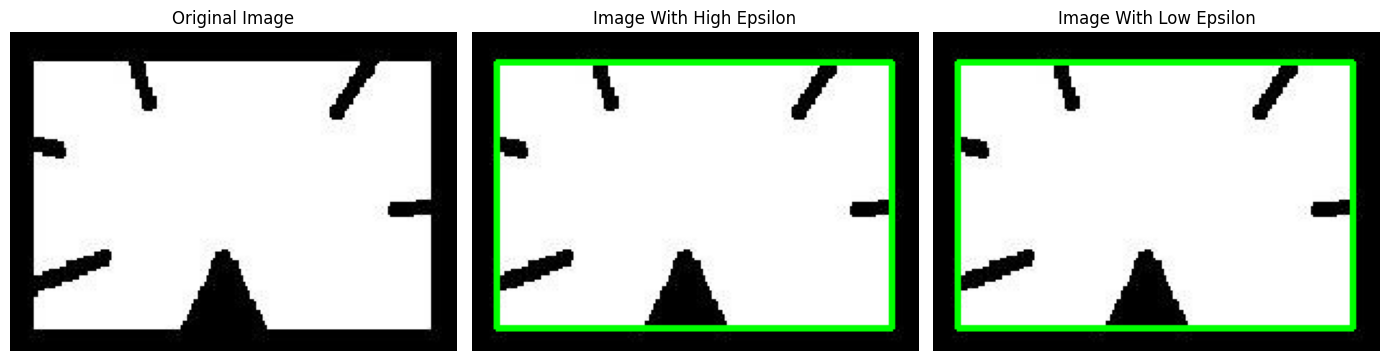

In [4]:
approx_image = cv2.imread(approx_path)
if approx_image is None:
  raise FileNotFoundError(f'Image Not Found: {approx_path}')

approx_gray = cv2.cvtColor(approx_image, cv2.COLOR_BGR2GRAY)

_, approx_binary = cv2.threshold(approx_gray, 127, 255, cv2.THRESH_BINARY)

approx_contours, approx_hierarchy = cv2.findContours(approx_binary, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)

if len(approx_contours) == 0:
  raise ValueError(f'No Contours Found In {approx_path}')

selected_contour = approx_contours[0]
perimeter = cv2.arcLength(selected_contour, True)

epsilon_high = 0.10 * perimeter
epsilon_low = 0.05 * perimeter

approx_epsilon_high = cv2.approxPolyDP(selected_contour, epsilon_high, True)
approx_epsilon_low = cv2.approxPolyDP(selected_contour, epsilon_low, True)

high_epsilon_image = approx_image.copy()
low_epsilon_image = approx_image.copy()

cv2.drawContours(high_epsilon_image, [approx_epsilon_high], 0, (0, 255, 0), 2)
cv2.drawContours(low_epsilon_image, [approx_epsilon_low], 0, (0, 255, 0), 2)

plt.figure(figsize=(14, 8))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(approx_image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(high_epsilon_image)
plt.title('Image With High Epsilon')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(low_epsilon_image)
plt.title('Image With Low Epsilon')
plt.axis('off')

plt.tight_layout()
plt.show()

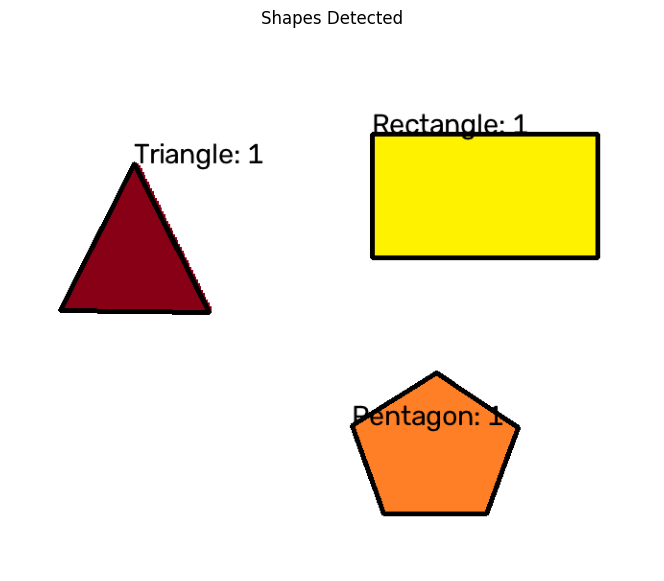

In [7]:
shapes2_image = cv2.imread(shapes2_path)
if shapes2_image is None:
  raise FileNotFoundError(f'Image Not Found: {shapes2_path}')

shapes2_gray = cv2.cvtColor(shapes2_image, cv2.COLOR_BGR2GRAY)

_, shapes2_binary = cv2.threshold(shapes2_gray, 245, 255, cv2.THRESH_BINARY_INV)

shapes2_contours, shapes2_hierarchy = cv2.findContours(shapes2_binary, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

shapes_results = shapes2_image.copy()
shape_counts = {}

for contour in shapes2_contours:
  perimeter = cv2.arcLength(contour, True)
  epsilon = 0.10 * perimeter
  approx = cv2.approxPolyDP(contour, epsilon, True)

  if len(approx) < 3:
    continue

  cv2.drawContours(shapes_results, [approx], 0, (0, 0, 0), 3)

  x, y = approx[0][0]
  vertex_count = len(approx)

  if vertex_count == 3:
    shape_name = 'Triangle'
  elif vertex_count == 4:
    shape_name = 'Rectangle'
  elif vertex_count == 5:
    shape_name = 'Pentagon'
  elif 6 <= vertex_count <= 10:
    shape_name = 'Hexagon'
  else:
    shape_name = 'Circle'

  shape_counts[shape_name] = shape_counts.get(shape_name, 0) + 1
  cv2.putText(shapes_results, f'{shape_name}: {shape_counts[shape_name]}', (int(x), int(y)), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 0), 1)

plt.figure(figsize=(9, 7))
plt.imshow(cv2.cvtColor(shapes_results, cv2.COLOR_BGR2RGB))
plt.title('Shapes Detected')
plt.axis('off')

plt.show()

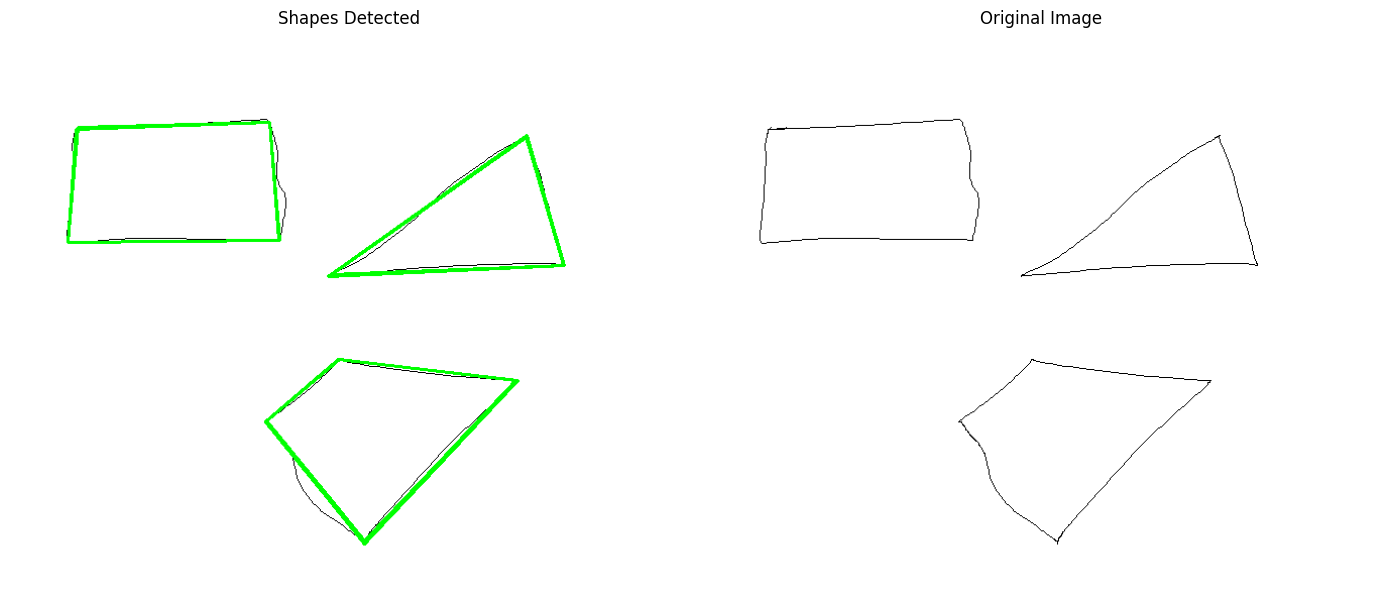

In [8]:
sketch_image = cv2.imread(sketch_path)
if sketch_image is None:
  raise FileNotFoundError(f'Image Not Found: {sketch_path}')

sketch_gray = cv2.cvtColor(sketch_image, cv2.COLOR_BGR2GRAY)

_, sketch_binary = cv2.threshold(sketch_gray, 127, 255, cv2.THRESH_BINARY_INV)

sketch_contours, sketch_hierarchy = cv2.findContours(sketch_binary.copy(), cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)

sketch_results = sketch_image.copy()

for contour in sketch_contours:
  perimeter = cv2.arcLength(contour, True)
  epsilon = 0.03 * perimeter
  approx = cv2.approxPolyDP(contour, epsilon, True)

  cv2.drawContours(sketch_results, [approx], 0, (0, 255, 0), 2)

plt.figure(figsize=(14, 8))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(sketch_results, cv2.COLOR_BGR2RGB))
plt.title('Shapes Detected')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sketch_image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.tight_layout()
plt.show()

In [9]:
output_images = {
    'Approx': approx_image,
    'Shapes2': shapes_results,
    'Sketch': sketch_results
}

for filename, output_image in output_images.items():
  output_path = f'/content/{filename}_output.png'
  cv2.imwrite(output_path, output_image)
  print(f'Saved: {output_path}')
  files.download(output_path)
  print(f'Downloaded: {output_path}')

Saved: /content/Approx_output.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: /content/Approx_output.png
Saved: /content/Shapes2_output.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: /content/Shapes2_output.png
Saved: /content/Sketch_output.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: /content/Sketch_output.png
